<a href="https://colab.research.google.com/github/Sanhith30/ITA0605-ML/blob/main/CO3-Assignment3/Assignment_3_CO3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ITA06 Machine Learning – Assignment 3 (CO3)

**Complete, question-wise Jupyter notebook**

This notebook is organised so that every question's calculations, output tables and visualisations appear immediately under that question. Figures are **not collected in one final cell**. Run the notebook from top to bottom.

## Requirements and reproducibility

Python 3.9+ with `numpy`, `pandas`, `matplotlib` and `scikit-learn`. The Bayesian calculations, Candidate Elimination, Naïve Bayes, Bayesian-network enumeration, EM updates, PAC calculations, Find-S, Halving and online conjunction learner are implemented directly. scikit-learn is used only as an independent Naïve Bayes verification.

Fixed random seeds are recorded in the relevant question sections. Generated datasets, CSV result tables, plots and a JSON summary are saved under `assignment3_outputs/` in the notebook's working directory. Synthetic data are experiments, not real industrial records.

**Notebook layout:** Each Q section contains a calculation/implementation cell followed by question-specific output cells. Tables and plots appear directly after the code that creates them.


## 0. Imports, reproducibility and output folders

In [1]:
import os, json, math, time, itertools, warnings
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

OUT=os.path.join(os.getcwd(),'assignment3_outputs')
FIG=os.path.join(OUT,'figures'); RES=os.path.join(OUT,'results')
os.makedirs(FIG,exist_ok=True); os.makedirs(RES,exist_ok=True)
SEED=20261105
rng=np.random.default_rng(SEED)
results={}


from IPython.display import display, Image
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 140)


## Q1 – Apply Bayes Theorem and Concept Learning to Hypothesis Selection (5 marks)

This question calculates the posterior probability of a bearing fault after one and two positive tests, then learns the concept **Fails Early** from D1–D6. The implementation displays Find-S and Candidate-Elimination traces, enumerates the D1–D3 version space, and compares uniform and non-uniform priors.


In [2]:
# ---------------- Q1: Bayes theorem + concept learning ----------------
prior_fault=0.03; sensitivity=0.95; fpr=0.08
p_pos=prior_fault*sensitivity+(1-prior_fault)*fpr
post1=prior_fault*sensitivity/p_pos
post2=post1*sensitivity/(post1*sensitivity+(1-post1)*fpr)
results['q1_bayes']={'P_positive':p_pos,'posterior_one_positive':post1,'posterior_two_independent_positives':post2,
                     'prior':prior_fault,'sensitivity':sensitivity,'false_positive_rate':fpr}

attrs=['Temperature','Load','Vibration']
domains=[['High','Normal'],['Heavy','Light'],['High','Low']]
D=[(('High','Heavy','High'),1,'D1'),(('High','Heavy','Low'),1,'D2'),(('Normal','Light','Low'),0,'D3'),
   (('High','Light','High'),0,'D4'),(('Normal','Heavy','High'),1,'D5'),(('Normal','Light','High'),0,'D6')]
# Standard conjunctive hypotheses: each coordinate in domain or '?' plus bottom all-None.
BOTTOM=(None,None,None); TOP=('?','?','?')
def covers(h,x):
    if h==BOTTOM: return False
    return all(v=='?' or v==xi for v,xi in zip(h,x))
def more_general_or_equal(h1,h2):
    # h1 >= h2
    if h2==BOTTOM: return True
    if h1==BOTTOM: return h2==BOTTOM
    return all(a=='?' or a==b for a,b in zip(h1,h2))
def min_generalize(s,x):
    if s==BOTTOM: return tuple(x)
    return tuple(a if a=='?' or a==xi else '?' for a,xi in zip(s,x))
def minimal_specializations(g,x,s):
    specs=[]
    for j,dom in enumerate(domains):
        if g[j]=='?':
            for v in dom:
                if v != x[j]:
                    h=list(g); h[j]=v; h=tuple(h)
                    if more_general_or_equal(h,s): specs.append(h)
    # unique
    return list(dict.fromkeys(specs))
def prune_general(G):
    out=[]
    for h in G:
        if not any(h!=g and more_general_or_equal(g,h) for g in G): out.append(h)
    return out
def candidate_elimination(examples):
    S=BOTTOM; G=[TOP]; trace=[]
    for x,y,name in examples:
        if y==1:
            G=[g for g in G if covers(g,x)]
            S=min_generalize(S,x)
        else:
            newG=[]
            for g in G:
                if covers(g,x): newG.extend(minimal_specializations(g,x,S))
                else: newG.append(g)
            G=prune_general(list(dict.fromkeys(newG)))
            if S!=BOTTOM: G=[g for g in G if more_general_or_equal(g,S)]
        trace.append({'example':name,'label':'Yes' if y else 'No','S':S,'G':tuple(G)})
    return S,G,trace
S6,G6,tr6=candidate_elimination(D)
S3,G3,tr3=candidate_elimination(D[:3])
# Find-S: ignore negatives, generalize only positives
s_find=BOTTOM; find_trace=[]
for x,y,name in D:
    if y: s_find=min_generalize(s_find,x)
    find_trace.append({'example':name,'label':'Yes' if y else 'No','S':s_find})
# enumerate version space after D1-D3 within H = product (domain values + ?), plus bottom
H=[tuple(h) for h in itertools.product(*[[*dom,'?'] for dom in domains])]
H.append(BOTTOM)
VS3=[h for h in H if all(covers(h,x)==bool(y) for x,y,_ in D[:3])]
# uniform prior: uniform over full H; posterior for consistent hypotheses uniform
post_uniform={str(h):1/len(VS3) for h in VS3}
# Non-uniform prior score 2^#wildcards, with 1.5 feature-reliability multiplier if Temperature is constrained.
def prior_weight(h):
    if h==BOTTOM: return 0.01
    k=sum(v=='?' for v in h)
    temp_factor=1.5 if h[0]!='?' else 1.0
    return (2.0**k)*temp_factor
weights=np.array([prior_weight(h) for h in VS3],float); weights/=weights.sum()
post_nonuniform={str(h):float(p) for h,p in zip(VS3,weights)}
# likelihood: 1 if consistent, 0 otherwise, hence all VS are ML
results['q1_concept']={
    'find_s_trace':find_trace,
    'candidate_elimination_D1_D6':tr6,
    'final_S':S6,'final_G':G6,
    'candidate_elimination_D1_D3':tr3,
    'VS_D1_D3':VS3,'version_space_size':len(VS3),
    'uniform_posterior':post_uniform,'nonuniform_posterior':post_nonuniform,
    'prior_definition':'weight(h) = 2^(number of ? constraints) * 1.5 if Temperature is constrained; bottom weight 0.01',
    'h_ML':'all hypotheses in version space (likelihood 1 under noise-free model)',
    'h_MAP':str(VS3[int(np.argmax(weights))]),
}



### Q1 results – Bayes theorem and maintenance records

In [3]:
# Bayes theorem results and the supplied maintenance examples
bayes_table = pd.DataFrame([
    {'Case':'Prior probability P(F)', 'Probability':prior_fault},
    {'Case':'One positive test: P(F | +)', 'Probability':post1},
    {'Case':'Two independent positives: P(F | ++)', 'Probability':post2},
    {'Case':'Probability of a positive test P(+)', 'Probability':p_pos},
])
display(bayes_table.style.format({'Probability':'{:.6f}'}))
maintenance_df = pd.DataFrame([{'ID':name,'Temperature':x[0],'Load':x[1],'Vibration':x[2],'Fails Early':'Yes' if y else 'No'} for x,y,name in D])
display(maintenance_df)


,Case,Probability
0,Prior probability P(F),0.030000
1,One positive test: P(F | +),0.268615
2,Two independent positives: P(F | ++),0.813478
3,Probability of a positive test P(+),0.106100


,ID,Temperature,Load,Vibration,Fails Early
0,D1,High,Heavy,High,Yes
1,D2,High,Heavy,Low,Yes
2,D3,Normal,Light,Low,No
3,D4,High,Light,High,No
4,D5,Normal,Heavy,High,Yes
5,D6,Normal,Light,High,No


### Q1 results – Find-S and Candidate-Elimination boundary traces

In [4]:
finds_df = pd.DataFrame([
    {'Example':r['example'],'Label':r['label'],'S after example':str(r['S'])}
    for r in find_trace
])
ce_df = pd.DataFrame([
    {'Example':r['example'],'Label':r['label'],'Specific boundary S':str(r['S']),
     'General boundary G':'; '.join(map(str,r['G'])) if r['G'] else '∅'}
    for r in tr6
])
print('Find-S trace')
display(finds_df)
print('Candidate-Elimination trace for D1–D6')
display(ce_df)
print('Final boundaries: S6 =', S6, '| G6 =', G6)


Find-S trace


,Example,Label,S after example
0,D1,Yes,"('High', 'Heavy', 'High')"
1,D2,Yes,"('High', 'Heavy', '?')"
2,D3,No,"('High', 'Heavy', '?')"
3,D4,No,"('High', 'Heavy', '?')"
4,D5,Yes,"('?', 'Heavy', '?')"
5,D6,No,"('?', 'Heavy', '?')"


Candidate-Elimination trace for D1–D6


,Example,Label,Specific boundary S,General boundary G
0,D1,Yes,"('High', 'Heavy', 'High')","('?', '?', '?')"
1,D2,Yes,"('High', 'Heavy', '?')","('?', '?', '?')"
2,D3,No,"('High', 'Heavy', '?')","('High', '?', '?'); ('?', 'Heavy', '?')"
3,D4,No,"('High', 'Heavy', '?')","('?', 'Heavy', '?')"
4,D5,Yes,"('?', 'Heavy', '?')","('?', 'Heavy', '?')"
5,D6,No,"('?', 'Heavy', '?')","('?', 'Heavy', '?')"


Final boundaries: S6 = ('?', 'Heavy', '?') | G6 = [('?', 'Heavy', '?')]


### Q1 results – D1–D3 version space, posterior table and lattice

,Hypothesis,Likelihood,Prior weight,Posterior (uniform prior),Posterior (non-uniform prior)
0,"('High', 'Heavy', '?')",1.000,3.000,0.3333,0.2308
1,"('High', '?', '?')",1.000,6.000,0.3333,0.4615
2,"('?', 'Heavy', '?')",1.000,4.000,0.3333,0.3077


Version-space size after D1–D3: 3 of 28 syntactic hypotheses.
h_ML: every hypothesis in VS3 has likelihood 1 under the noise-free likelihood.
h_MAP under the stated non-uniform prior: ('High', '?', '?')
Posterior-predictive query: ('High', 'Light', 'High') | P(Yes | D, query)= 0.461538 | combined vote = No


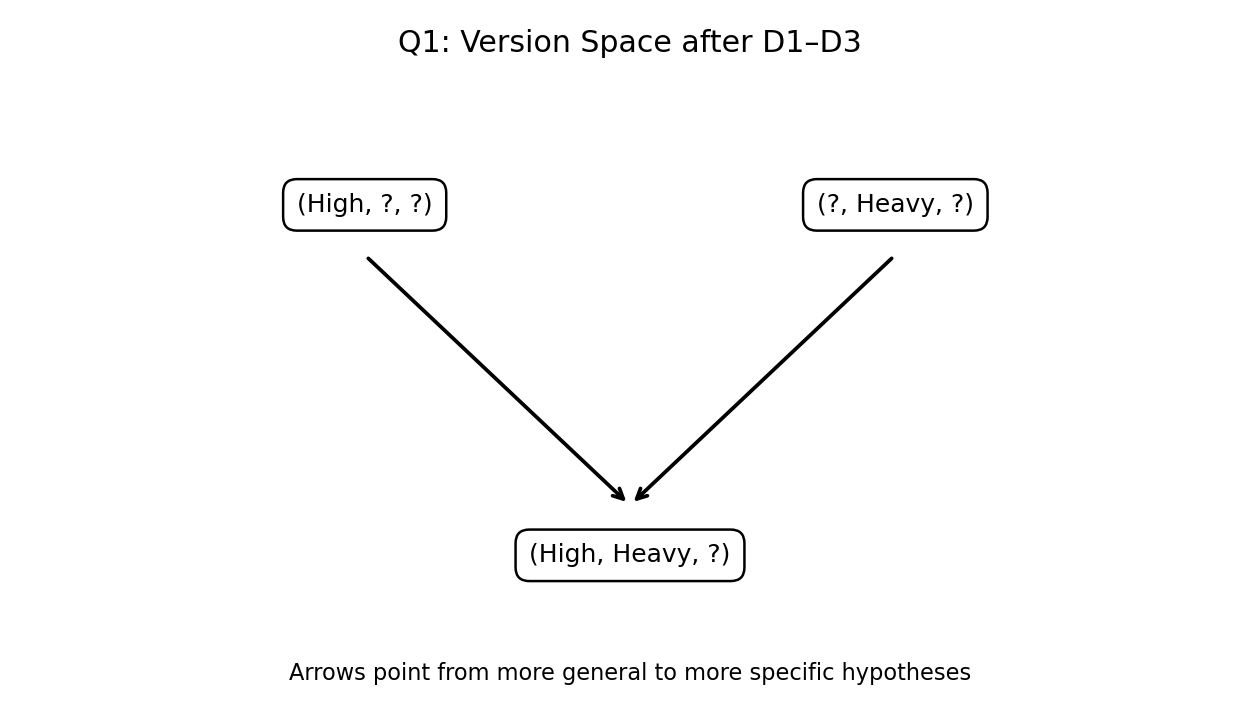

In [5]:
# Posterior-predictive illustration and hypothesis posterior table
q1_query=('High','Light','High')
q1_query_votes={str(h):('Yes' if covers(h,q1_query) else 'No') for h in VS3}
q1_query_p_yes=float(sum(p for h,p in zip(VS3,weights) if covers(h,q1_query)))
results['q1_concept']['posterior_predictive_example']={
    'query':q1_query,'hypothesis_votes':q1_query_votes,'posterior_probability_yes':q1_query_p_yes,
    'combined_prediction':'Yes' if q1_query_p_yes>0.5 else 'No',
    'MAP_prediction':'Yes' if covers(tuple(VS3[int(np.argmax(weights))]),q1_query) else 'No'}
results['q1_concept']['hypothesis_space_size']=len(H)

prior_values=np.array([prior_weight(h) for h in VS3],dtype=float)
posterior_rows=[]
for h,prior_w,p_uni,p_non in zip(VS3,prior_values,post_uniform.values(),weights):
    posterior_rows.append({'Hypothesis':str(h),'Likelihood':1.0,'Prior weight':prior_w,
                           'Posterior (uniform prior)':p_uni,'Posterior (non-uniform prior)':float(p_non)})
vs_df=pd.DataFrame(posterior_rows)
display(vs_df.style.format({'Likelihood':'{:.3f}','Prior weight':'{:.3f}',
                            'Posterior (uniform prior)':'{:.4f}','Posterior (non-uniform prior)':'{:.4f}'}))
print('Version-space size after D1–D3:', len(VS3), 'of', len(H), 'syntactic hypotheses.')
print('h_ML: every hypothesis in VS3 has likelihood 1 under the noise-free likelihood.')
print('h_MAP under the stated non-uniform prior:', results['q1_concept']['h_MAP'])
print('Posterior-predictive query:', q1_query, '| P(Yes | D, query)=', round(q1_query_p_yes,6),
      '| combined vote =', results['q1_concept']['posterior_predictive_example']['combined_prediction'])

# Draw the D1–D3 version-space lattice in this Q1 section.
fig,ax=plt.subplots(figsize=(7,4)); ax.axis('off')
latpos={"('High', '?', '?')":(.28,.78),"('?', 'Heavy', '?')":(.72,.78),"('High', 'Heavy', '?')":(.5,.22)}
for label,(x0,y0) in latpos.items():
    ax.text(x0,y0,label.replace("'",''),ha='center',va='center',fontsize=10,
            bbox=dict(boxstyle='round,pad=.55',fc='white',ec='black'))
for u,v in [("('High', '?', '?')","('High', 'Heavy', '?')"),("('?', 'Heavy', '?')","('High', 'Heavy', '?')")]:
    x1,y1=latpos[u]; x2,y2=latpos[v]
    ax.annotate('',xy=(x2,y2+.08),xytext=(x1,y1-.08),arrowprops=dict(arrowstyle='->',lw=1.5))
ax.text(.5,.02,'Arrows point from more general to more specific hypotheses',ha='center',fontsize=9)
ax.set_title('Q1: Version Space after D1–D3'); fig.tight_layout()
q1_fig=os.path.join(FIG,'q1_version_space_lattice.png'); fig.savefig(q1_fig,dpi=180); plt.close(fig)
display(Image(filename=q1_fig))


## Q2 – Compare MDL, Bayes Optimal Classifier and Gibbs Algorithm (5 marks)

This section calculates the description length of Trees A and B, the node-cost reversal point, posterior-weighted class votes for X, and the expected errors of Gibbs and Bayes-optimal prediction. The Monte Carlo verification uses 200,000 draws with seed 4202.


In [6]:
# ---------------- Q2: MDL, Bayes optimal and Gibbs ----------------
log200=math.log2(200); nodecost=12
A_nodes,A_errors=6,8; B_nodes,B_errors=25,1
LA=A_nodes*nodecost+A_errors*log200
LB=B_nodes*nodecost+B_errors*log200
crossover=(A_errors-B_errors)*log200/(B_nodes-A_nodes)
hyps=[('h1',.30,1),('h2',.25,0),('h3',.20,0),('h4',.15,1),('h5',.10,0)]
p_plus=sum(p for _,p,y in hyps if y==1); p_minus=1-p_plus
bayes_pred=1 if p_plus>p_minus else 0
map_h=max(hyps,key=lambda z:z[1])
gibbs_expected=2*p_plus*p_minus
bayes_expected=min(p_plus,p_minus)
rng_q2=np.random.default_rng(4202)
n_mc=200_000
probs=np.array([x[1] for x in hyps]); labels=np.array([x[2] for x in hyps])
i_true=rng_q2.choice(len(hyps),size=n_mc,p=probs)
i_draw=rng_q2.choice(len(hyps),size=n_mc,p=probs)
mc_error=float(np.mean(labels[i_true]!=labels[i_draw]))
results['q2']={'tree_A_bits':LA,'tree_B_bits':LB,'preferred_tree':'A' if LA<LB else 'B','node_cost_reversal_bits':crossover,
 'posterior_plus':p_plus,'posterior_minus':p_minus,'bayes_optimal_prediction':'+' if bayes_pred else '-',
 'MAP_hypothesis':map_h[0],'MAP_prediction':'+' if map_h[2] else '-',
 'gibbs_expected_error':gibbs_expected,'bayes_optimal_expected_error':bayes_expected,
 'gibbs_upper_bound_2_bayes':2*bayes_expected,'monte_carlo_draws':n_mc,'monte_carlo_gibbs_error':mc_error}



### Q2 results – MDL, posterior voting and expected error

,Tree,Nodes,Training errors,Model cost (bits),Data cost (bits),Total description length (bits)
0,A,6.0000,8.0000,72.0000,61.1508,133.1508
1,B,25.0000,1.0000,300.0000,7.6439,307.6439


MDL reversal point: 2.816158 bits per node. Current node cost = 12 bits.


,Hypothesis,Posterior P(h|D),Prediction for X
0,h1,0.30,+
1,h2,0.25,-
2,h3,0.20,-
3,h4,0.15,+
4,h5,0.10,-


,Class,Weighted posterior vote
0,+,0.4500
1,−,0.5500


,Classifier,Expected error
0,Gibbs,0.495000
1,Bayes optimal,0.450000
2,2 × Bayes-optimal error bound,0.900000
3,"Gibbs Monte Carlo (200,000 draws)",0.494505


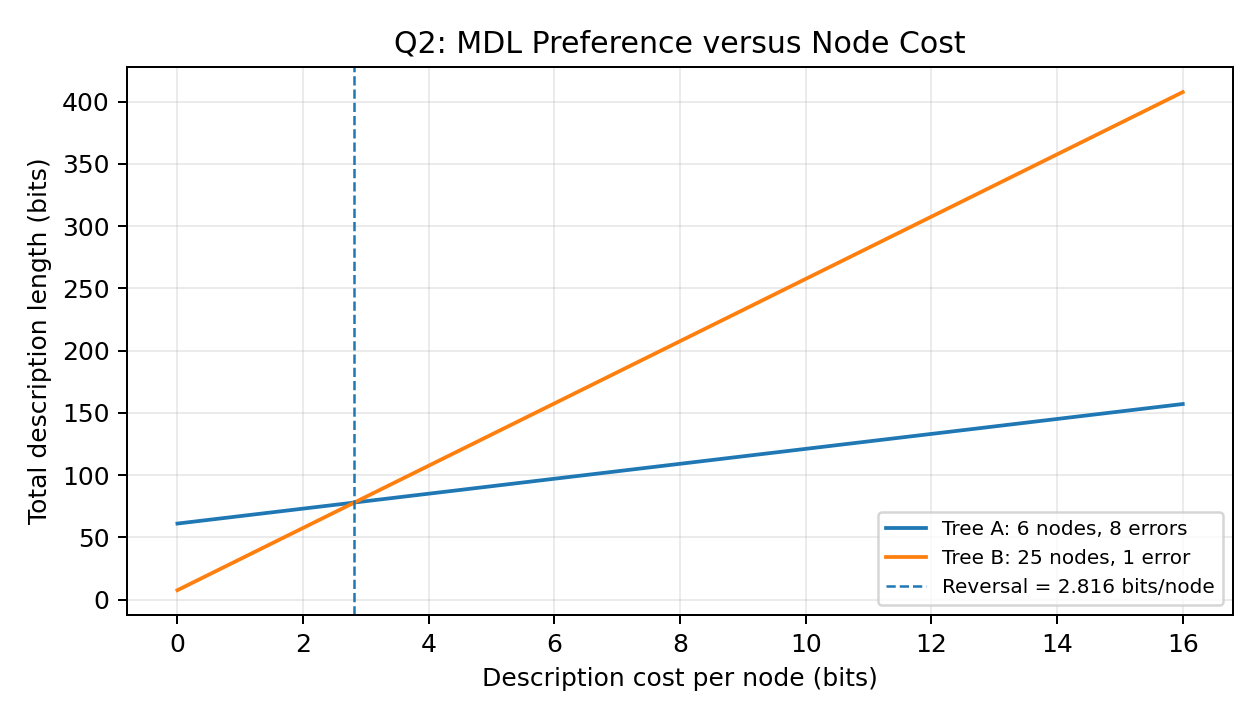

In [7]:
mdl_table=pd.DataFrame([
    {'Tree':'A','Nodes':A_nodes,'Training errors':A_errors,'Model cost (bits)':A_nodes*nodecost,
     'Data cost (bits)':A_errors*log200,'Total description length (bits)':LA},
    {'Tree':'B','Nodes':B_nodes,'Training errors':B_errors,'Model cost (bits)':B_nodes*nodecost,
     'Data cost (bits)':B_errors*log200,'Total description length (bits)':LB},
])
display(mdl_table.style.format({c:'{:.4f}' for c in mdl_table.select_dtypes('number').columns}))
print(f'MDL reversal point: {crossover:.6f} bits per node. Current node cost = {nodecost} bits.')

vote_table=pd.DataFrame([{'Hypothesis':name,'Posterior P(h|D)':p,'Prediction for X':'+' if y else '-'} for name,p,y in hyps])
display(vote_table.style.format({'Posterior P(h|D)':'{:.2f}'}))
weighted_votes=pd.DataFrame([
    {'Class':'+','Weighted posterior vote':p_plus},
    {'Class':'−','Weighted posterior vote':p_minus},
])
display(weighted_votes.style.format({'Weighted posterior vote':'{:.4f}'}))
error_table=pd.DataFrame([
    {'Classifier':'Gibbs','Expected error':gibbs_expected},
    {'Classifier':'Bayes optimal','Expected error':bayes_expected},
    {'Classifier':'2 × Bayes-optimal error bound','Expected error':2*bayes_expected},
    {'Classifier':'Gibbs Monte Carlo (200,000 draws)','Expected error':mc_error},
])
display(error_table.style.format({'Expected error':'{:.6f}'}))

# Q2 node-cost sensitivity graph, generated and displayed here.
cs=np.linspace(0,16,161)
mdlA=A_nodes*cs+A_errors*log200
mdlB=B_nodes*cs+B_errors*log200
fig,ax=plt.subplots(figsize=(7,4))
ax.plot(cs,mdlA,label='Tree A: 6 nodes, 8 errors')
ax.plot(cs,mdlB,label='Tree B: 25 nodes, 1 error')
ax.axvline(crossover,linestyle='--',linewidth=1,label=f'Reversal = {crossover:.3f} bits/node')
ax.set_xlabel('Description cost per node (bits)'); ax.set_ylabel('Total description length (bits)')
ax.set_title('Q2: MDL Preference versus Node Cost'); ax.legend(fontsize=8); ax.grid(alpha=.25)
fig.tight_layout(); q2_fig=os.path.join(FIG,'q2_mdl_sensitivity.png'); fig.savefig(q2_fig,dpi=180); plt.close(fig)
display(Image(filename=q2_fig))


## Q3 – Build and Evaluate a Naïve Bayes Classifier (6 marks)

The custom categorical Naïve Bayes model is fitted to the ten loan applications in the brief. This section presents class priors and conditional probability tables, the two manual classifications, the unseen `Very High` income case with Laplace smoothing, library verification, and the 4,000-row correlated-feature experiment.


In [8]:
# ---------------- Q3: Naive Bayes implementation ----------------
loan=[
 ('High','Salaried','Good','Yes'),('High','Self-employed','Good','Yes'),('Medium','Salaried','Good','Yes'),
 ('Medium','Self-employed','Poor','No'),('Low','Salaried','Poor','No'),('Low','Self-employed','Poor','No'),
 ('Medium','Salaried','Poor','Yes'),('Low','Salaried','Good','Yes'),('High','Self-employed','Poor','No'),('Low','Self-employed','Good','No')]
loan_df=pd.DataFrame(loan,columns=['Income','Employment','CreditHistory','Approve'])
features=['Income','Employment','CreditHistory']; classes=['Yes','No']
cats={'Income':['Low','Medium','High','Very High'],'Employment':['Salaried','Self-employed'],'CreditHistory':['Good','Poor']}
def nb_fit(df,features,alpha=0.0,categories=None):
    categories=categories or {f:sorted(df[f].unique().tolist()) for f in features}
    cls_counts=df['Approve'].value_counts().to_dict(); N=len(df)
    model={'classes':classes,'priors':{},'cond':{},'categories':categories,'alpha':alpha}
    for c in classes:
        nc=cls_counts.get(c,0); model['priors'][c]=nc/N
        model['cond'][c]={}
        for f in features:
            model['cond'][c][f]={}
            K=len(categories[f])
            for v in categories[f]:
                count=int(((df['Approve']==c)&(df[f]==v)).sum())
                denom=nc+alpha*K
                model['cond'][c][f][v]=(count+alpha)/denom if denom else 0.0
    return model
def nb_predict_proba(model,row,features):
    log_scores={}
    for c in classes:
        p=model['priors'][c]
        logp=math.log(p) if p>0 else -np.inf
        for f in features:
            pv=model['cond'][c][f].get(row[f],0.0)
            logp+=math.log(pv) if pv>0 else -np.inf
        log_scores[c]=logp
    mx=max(log_scores.values()); exps={c:math.exp(v-mx) if np.isfinite(v) else 0.0 for c,v in log_scores.items()}
    den=sum(exps.values()); return {c:exps[c]/den if den else np.nan for c in classes}, log_scores
nb_model=nb_fit(loan_df,features,alpha=0.0,categories=cats)
manual={}
for label,row in [('x1',{'Income':'Low','Employment':'Self-employed','CreditHistory':'Poor'}),('x2',{'Income':'Medium','Employment':'Salaried','CreditHistory':'Good'})]:
    probs_out,logs=nb_predict_proba(nb_model,row,features)
    scores={c:math.exp(v) if np.isfinite(v) else 0.0 for c,v in logs.items()}
    manual[label]={'row':row,'scores':scores,'posterior':probs_out,'prediction':max(probs_out,key=probs_out.get)}
# unseen value without smoothing and with alpha=1
unseen={'Income':'Very High','Employment':'Salaried','CreditHistory':'Good'}
_,logs_mle=nb_predict_proba(nb_model,unseen,features)
nb_smooth=nb_fit(loan_df,features,alpha=1.0,categories=cats)
post_smooth,logs_smooth=nb_predict_proba(nb_smooth,unseen,features)
scores_smooth={c:math.exp(v) if np.isfinite(v) else 0.0 for c,v in logs_smooth.items()}
# Synthetic correlation experiment. Y drives a binary base feature, redundant copy flips with 5% probability.
rng_nb=np.random.default_rng(3303); N=4000
Y=rng_nb.binomial(1,.5,N)
# informative signal: P(X1=Y)=0.82
X1=np.where(rng_nb.random(N)<.82,Y,1-Y)
# redundant feature is a noisy duplicate of X1 (strongly correlated with X1)
X2=np.where(rng_nb.random(N)<.97,X1,1-X1)
# independent weak signal P(X3=Y)=.60
X3=np.where(rng_nb.random(N)<.60,Y,1-Y)
# fixed 70/30 split via deterministic shuffle
idx=np.arange(N); rng_nb.shuffle(idx); tr=idx[:2800]; te=idx[2800:]
# Save the complete generated dataset with its split assignment for reproducibility.
split_labels=np.full(N,'test',dtype=object); split_labels[tr]='train'
pd.DataFrame({'X1_signal':X1,'X2_redundant_copy':X2,'X3_weak_signal':X3,
              'Target':Y,'Split':split_labels}).to_csv(os.path.join(RES,'q3_correlated_features_4000.csv'),index=False)
# binary NB helper
def fit_binary_nb(X,y,alpha=1.0):
    model={'prior':float(np.mean(y)),'cond':{}}
    for j in range(X.shape[1]):
        model['cond'][j]={}
        for c in [0,1]:
            vals=X[y==c,j]; model['cond'][j][c]=[(int(np.sum(vals==v))+alpha)/(len(vals)+2*alpha) for v in [0,1]]
    return model
def pred_binary_nb(model,X):
    out=[]
    for row in X:
        logs=[]
        for c in [0,1]:
            p=model['prior'] if c==1 else 1-model['prior']; lp=math.log(p)
            for j,v in enumerate(row): lp+=math.log(model['cond'][j][c][int(v)])
            logs.append(lp)
        mx=max(logs); e=np.exp(np.array(logs)-mx); out.append(e[1]/e.sum())
    return np.array(out)
def metrics_binary(y,p):
    pred=(p>=.5).astype(int); acc=float(np.mean(pred==y)); eps=1e-15
    ll=float(-np.mean(y*np.log(np.clip(p,eps,1-eps))+(1-y)*np.log(np.clip(1-p,eps,1-eps))))
    return {'accuracy':acc,'log_loss':ll}
exp_nb=[]
for name,cols in [('without_redundant',[0,2]),('with_redundant',[0,1,2])]:
    m=fit_binary_nb(np.column_stack([X1,X2,X3])[tr][:,cols],Y[tr],alpha=1.0)
    p=pred_binary_nb(m,np.column_stack([X1,X2,X3])[te][:,cols])
    mt=metrics_binary(Y[te],p); exp_nb.append({'model':name,**mt})
results['q3']={'class_priors':{c:float(np.mean(loan_df.Approve==c)) for c in classes},
 'conditional_tables':nb_model['cond'],'manual_predictions':manual,'unseen_mle_log_scores':logs_mle,
 'unseen_alpha_1_scores':scores_smooth,'unseen_alpha_1_posterior':post_smooth,'alpha':1.0,'income_categories':cats['Income'],
 'redundant_feature_experiment':exp_nb,'synthetic_seed':3303,'synthetic_N':N,'train_size':len(tr),'test_size':len(te)}
loan_df.to_csv(os.path.join(RES,'q3_loan_data.csv'),index=False)

# Optional sklearn verification using categorical integer encoding and alpha=1
try:
    from sklearn.naive_bayes import CategoricalNB
    enc_maps={f:{v:i for i,v in enumerate(cats[f])} for f in features}
    X_train=np.array([[enc_maps[f][row[f]] for f in features] for _,row in loan_df.iterrows()],dtype=int)
    y_train=(loan_df.Approve=='Yes').astype(int).values
    sk=CategoricalNB(alpha=1.0,fit_prior=True,min_categories=[len(cats[f]) for f in features])
    sk.fit(X_train,y_train)
    testrow=np.array([[enc_maps[f][unseen[f]] for f in features]],dtype=int)
    skprob=sk.predict_proba(testrow)[0].tolist()
    results['q3']['sklearn_alpha1_unseen_posterior']={'No':skprob[0],'Yes':skprob[1]}
except Exception as e:
    results['q3']['sklearn_verification_error']=str(e)



### Q3 results – supplied loan records and probability tables

In [9]:
display(loan_df)
prior_table=pd.DataFrame([{'Class':c,'Count':int((loan_df.Approve==c).sum()),'Prior P(class)':nb_model['priors'][c]} for c in classes])
display(prior_table.style.format({'Prior P(class)':'{:.4f}'}))
conditional_rows=[]
for cls in classes:
    for feature in features:
        for value,prob in nb_model['cond'][cls][feature].items():
            conditional_rows.append({'Class':cls,'Feature':feature,'Value':value,'Conditional probability':prob})
conditional_df=pd.DataFrame(conditional_rows)
display(conditional_df.style.format({'Conditional probability':'{:.4f}'}))


,Income,Employment,CreditHistory,Approve
0,High,Salaried,Good,Yes
1,High,Self-employed,Good,Yes
2,Medium,Salaried,Good,Yes
3,Medium,Self-employed,Poor,No
4,Low,Salaried,Poor,No
5,Low,Self-employed,Poor,No
6,Medium,Salaried,Poor,Yes
7,Low,Salaried,Good,Yes
8,High,Self-employed,Poor,No
9,Low,Self-employed,Good,No


,Class,Count,Prior P(class)
0,Yes,5,0.5000
1,No,5,0.5000


,Class,Feature,Value,Conditional probability
0,Yes,Income,Low,0.2000
1,Yes,Income,Medium,0.4000
2,Yes,Income,High,0.4000
3,Yes,Income,Very High,0.0000
4,Yes,Employment,Salaried,0.8000
5,Yes,Employment,Self-employed,0.2000
6,Yes,CreditHistory,Good,0.8000
7,Yes,CreditHistory,Poor,0.2000
8,No,Income,Low,0.6000
9,No,Income,Medium,0.2000


### Q3 results – manual cases, unseen-value smoothing and library check

In [10]:
manual_rows=[]
for key,item in manual.items():
    manual_rows.append({'Case':key,'Input':str(item['row']),'Score Yes':item['scores']['Yes'],
                        'Score No':item['scores']['No'],'Posterior Yes':item['posterior']['Yes'],
                        'Posterior No':item['posterior']['No'],'Prediction':item['prediction']})
manual_df=pd.DataFrame(manual_rows)
display(manual_df.style.format({c:'{:.6f}' for c in ['Score Yes','Score No','Posterior Yes','Posterior No']}))
unseen_df=pd.DataFrame([
    {'Case':'Unseen value, MLE','Log score Yes':logs_mle['Yes'],'Log score No':logs_mle['No'],
     'Posterior Yes':np.nan,'Posterior No':np.nan},
    {'Case':'Unseen value, Laplace alpha=1','Log score Yes':logs_smooth['Yes'],'Log score No':logs_smooth['No'],
     'Posterior Yes':post_smooth['Yes'],'Posterior No':post_smooth['No']},
])
display(unseen_df.style.format({c:'{:.6f}' for c in ['Log score Yes','Log score No','Posterior Yes','Posterior No']}))
print('scikit-learn alpha=1 verification:', results['q3'].get('sklearn_alpha1_unseen_posterior'))

# Also verify the two observed queries with matching alpha=0, if library support is available.
try:
    from sklearn.naive_bayes import CategoricalNB
    sk_mle=CategoricalNB(alpha=0.0,fit_prior=True,min_categories=[len(cats[f]) for f in features])
    sk_mle.fit(X_train,y_train)
    mle_checks={}
    for key,row in [('x1',manual['x1']['row']),('x2',manual['x2']['row'])]:
        xx=np.array([[enc_maps[f][row[f]] for f in features]],dtype=int)
        pp=sk_mle.predict_proba(xx)[0]
        mle_checks[key]={'No':float(pp[0]),'Yes':float(pp[1])}
    results['q3']['sklearn_alpha0_manual_checks']=mle_checks
except Exception as exc:
    results['q3']['sklearn_alpha0_manual_verification_error']=str(exc)
print('scikit-learn alpha=0 verification:', results['q3'].get('sklearn_alpha0_manual_checks'))


,Case,Input,Score Yes,Score No,Posterior Yes,Posterior No,Prediction
0,x1,"{'Income': 'Low', 'Employment': 'Self-employed', 'CreditHistory': 'Poor'}",0.004000,0.192000,0.020408,0.979592,No
1,x2,"{'Income': 'Medium', 'Employment': 'Salaried', 'CreditHistory': 'Good'}",0.128000,0.004000,0.969697,0.030303,Yes


,Case,Log score Yes,Log score No,Posterior Yes,Posterior No
0,"Unseen value, MLE",-inf,-inf,nan,nan
1,"Unseen value, Laplace alpha=1",-3.563316,-5.395898,0.862069,0.137931


scikit-learn alpha=1 verification: {'No': 0.13793103448275862, 'Yes': 0.8620689655172415}
scikit-learn alpha=0 verification: {'x1': {'No': 0.9795918367346939, 'Yes': 0.020408163265306135}, 'x2': {'No': 0.030303030303030318, 'Yes': 0.9696969696969697}}


/usr/local/lib/python3.13/dist-packages/sklearn/naive_bayes.py:1528: RuntimeWarning: divide by zero encountered in log
  np.log(smoothed_cat_count) - np.log(smoothed_class_count.reshape(-1, 1))


### Q3 results – redundant-feature experiment and comparison graph

,model,accuracy,log_loss
0,without_redundant,0.8275,0.453632
1,with_redundant,0.8225,0.551920


Generated dataset: /content/assignment3_outputs/results/q3_correlated_features_4000.csv | train rows = 2800 | test rows = 1200 | seed = 3303


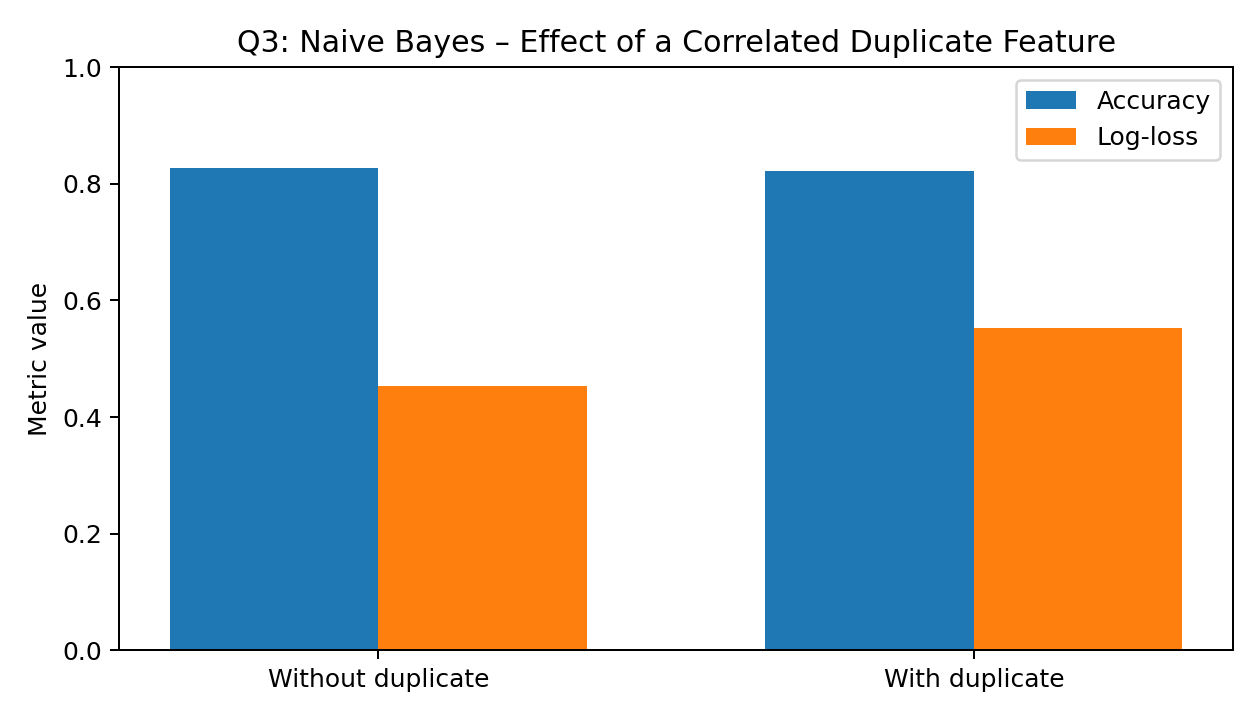

In [11]:
experiment_df=pd.DataFrame(exp_nb)
display(experiment_df.style.format({'accuracy':'{:.4f}','log_loss':'{:.6f}'}))
print('Generated dataset:', os.path.join(RES,'q3_correlated_features_4000.csv'),
      '| train rows =',len(tr),'| test rows =',len(te),'| seed = 3303')

fig,ax=plt.subplots(figsize=(7,4))
labels=['Without duplicate','With duplicate']
accs=[exp_nb[0]['accuracy'],exp_nb[1]['accuracy']]
losses=[exp_nb[0]['log_loss'],exp_nb[1]['log_loss']]
xx=np.arange(2); w=.35
ax.bar(xx-w/2,accs,w,label='Accuracy'); ax.bar(xx+w/2,losses,w,label='Log-loss')
ax.set_xticks(xx,labels); ax.set_ylim(0,1); ax.set_ylabel('Metric value')
ax.set_title('Q3: Naive Bayes – Effect of a Correlated Duplicate Feature')
ax.legend(); fig.tight_layout(); q3_fig=os.path.join(FIG,'q3_redundant_feature_comparison.png')
fig.savefig(q3_fig,dpi=180); plt.close(fig)
display(Image(filename=q3_fig))


## Q4 – Model and Query a Bayesian Belief Network (6 marks)

This section defines the five-variable production-line network, performs exact inference by enumeration, examines d-separation and explaining away, simulates 1,000 records, and estimates conditional probability tables at sample sizes 50, 200 and 1,000.


In [12]:
# ---------------- Q4 Bayesian belief network ----------------
# Enumeration order P,C,O,A,S; all bool values
pP=.10; pC=.05
pO={(1,1):.95,(1,0):.60,(0,1):.80,(0,0):.02}
pA={1:.90,0:.05}; pS={1:.70,0:.01}
def joint_prob(P,C,O,A,S):
    pp=pP if P else 1-pP; pc=pC if C else 1-pC
    po=pO[(P,C)] if O else 1-pO[(P,C)]
    pa=pA[O] if A else 1-pA[O]
    ps=pS[O] if S else 1-pS[O]
    return pp*pc*po*pa*ps
states=list(itertools.product([0,1],repeat=5))
def marginal(query,evidence=None):
    evidence=evidence or {}; num=den=0.0; nnum=nden=0
    for st in states:
        d=dict(zip(['P','C','O','A','S'],st))
        if any(d[k]!=v for k,v in evidence.items()): continue
        pr=joint_prob(*st); den+=pr; nden+=1
        if all(d[k]==v for k,v in query.items()): num+=pr; nnum+=1
    return (num/den if den else np.nan),num,den,nnum,nden
pO_m=marginal({'O':1})
pC_A=marginal({'C':1},{'A':1})
pC_AP=marginal({'C':1},{'A':1,'P':1})
# Simulation of BN
rng_bn=np.random.default_rng(4404); NN=1000
sim=[]
for _ in range(NN):
    P=int(rng_bn.random()<pP); C=int(rng_bn.random()<pC)
    O=int(rng_bn.random()<pO[(P,C)]); A=int(rng_bn.random()<pA[O]); S=int(rng_bn.random()<pS[O])
    sim.append((P,C,O,A,S))
bn_df=pd.DataFrame(sim,columns=['P','C','O','A','S'])
bn_df.to_csv(os.path.join(RES,'q4_bn_simulated_1000.csv'),index=False)
# Estimate all CPTs MLE at sample sizes, compare O CPT MAE against truth
est_rows=[]
for n in [50,200,1000]:
    sample=bn_df.iloc[:n]
    eP=sample.P.mean(); eC=sample.C.mean()
    eO={}
    for pv,cv in itertools.product([0,1],repeat=2):
        sub=sample[(sample.P==pv)&(sample.C==cv)]
        eO[(pv,cv)]=float(sub.O.mean()) if len(sub) else np.nan
    eA={o:float(sample[sample.O==o].A.mean()) if np.sum(sample.O==o)>0 else np.nan for o in [0,1]}
    eS={o:float(sample[sample.O==o].S.mean()) if np.sum(sample.O==o)>0 else np.nan for o in [0,1]}
    mae=float(np.nanmean([abs(eO[k]-pO[k]) for k in pO]))
    est_rows.append({'N':n,'P(P=T)':eP,'P(C=T)':eC,'P(A=T|O=F)':eA[0],'P(A=T|O=T)':eA[1],
                     'P(S=T|O=F)':eS[0],'P(S=T|O=T)':eS[1],
                     **{f'P(O=T|P={k[0]},C={k[1]})':eO[k] for k in eO},'O_CPT_MAE':mae})
pd.DataFrame(est_rows).to_csv(os.path.join(RES,'q4_cpt_estimates.csv'),index=False)
results['q4']={'P_O_true':pO_m[0],'P_C_given_A':pC_A[0],'P_C_given_A_P':pC_AP[0],
 'enumeration_terms':{'P(O=T)':{'numerator':pO_m[3],'denominator':pO_m[4]},
                      'P(C=T|A=T)':{'numerator':pC_A[3],'denominator':pC_A[4]},
                      'P(C=T|A=T,P=T)':{'numerator':pC_AP[3],'denominator':pC_AP[4]}},
 'parameter_count_bn':10,'full_joint_parameters':31,'cpt_estimates':est_rows,'seed':4404}
# Network diagram
fig,ax=plt.subplots(figsize=(8,4)); ax.axis('off')
pos={'P':(.15,.75),'C':(.15,.25),'O':(.50,.50),'A':(.85,.75),'S':(.85,.25)}
for node,(x,y) in pos.items():
    ax.text(x,y,node,ha='center',va='center',fontsize=14,bbox=dict(boxstyle='round,pad=0.55',fc='white',ec='black',lw=1.5))
for u,v in [('P','O'),('C','O'),('O','A'),('O','S')]:
    x1,y1=pos[u]; x2,y2=pos[v]; ax.annotate('',xy=(x2-.06*np.sign(x2-x1),y2),xytext=(x1+.06*np.sign(x2-x1),y1),arrowprops=dict(arrowstyle='->',lw=1.6))
ax.set_title('Bayesian Belief Network: Production-line Alarm'); fig.tight_layout(); fig.savefig(os.path.join(FIG,'q4_bayesian_network.png'),dpi=180); plt.close(fig)



### Q4 results – Bayesian network diagram and parameterisation

Joint factorisation: P(P,C,O,A,S) = P(P) P(C) P(O|P,C) P(A|O) P(S|O)


,CPT,Independent parameters
0,P(P),1
1,P(C),1
2,"P(O | P,C)",4
3,P(A | O),2
4,P(S | O),2
5,Total Bayesian network,10
6,Full joint over 5 binary variables,31


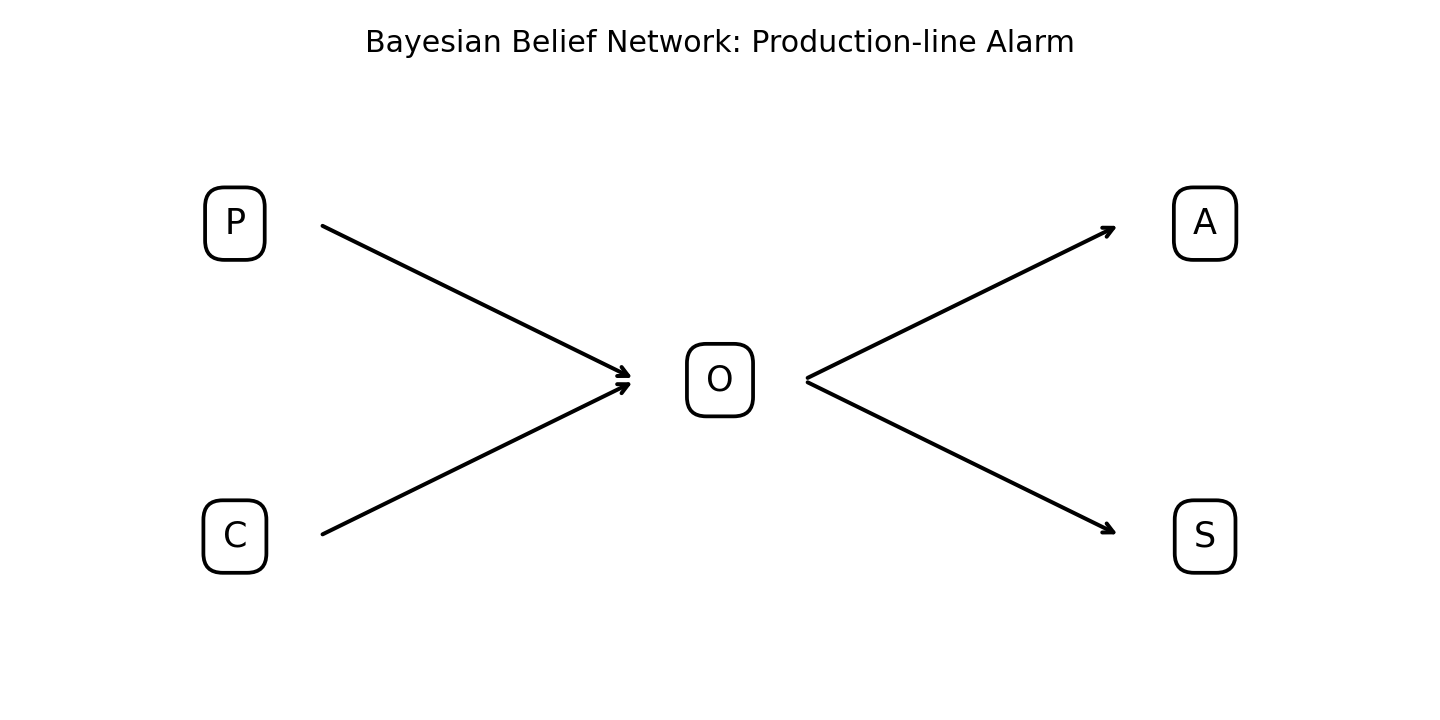

In [13]:
print('Joint factorisation: P(P,C,O,A,S) = P(P) P(C) P(O|P,C) P(A|O) P(S|O)')
parameter_table=pd.DataFrame([
    {'CPT':'P(P)','Independent parameters':1},
    {'CPT':'P(C)','Independent parameters':1},
    {'CPT':'P(O | P,C)','Independent parameters':4},
    {'CPT':'P(A | O)','Independent parameters':2},
    {'CPT':'P(S | O)','Independent parameters':2},
    {'CPT':'Total Bayesian network','Independent parameters':10},
    {'CPT':'Full joint over 5 binary variables','Independent parameters':31},
])
display(parameter_table)
q4_fig=os.path.join(FIG,'q4_bayesian_network.png')
display(Image(filename=q4_fig))


### Q4 results – d-separation and exact inference

In [14]:
dsep_df=pd.DataFrame([
    {'Claim':'A independent of S given O','Holds':'Yes','Reason':'Separate children of O; conditioning on O blocks the common-cause path.'},
    {'Claim':'P independent of C with no evidence','Holds':'Yes','Reason':'Independent root variables.'},
    {'Claim':'P independent of C given O','Holds':'No','Reason':'O is a collider; conditioning opens the path (explaining away).'},
    {'Claim':'P independent of C given A','Holds':'No','Reason':'A is a descendant of collider O; observing it opens the path.'},
])
display(dsep_df)
query_df=pd.DataFrame([
    {'Query':'P(O=T)','Numerator terms':pO_m[3],'Denominator terms':pO_m[4],'Probability':pO_m[0]},
    {'Query':'P(C=T | A=T)','Numerator terms':pC_A[3],'Denominator terms':pC_A[4],'Probability':pC_A[0]},
    {'Query':'P(C=T | A=T, P=T)','Numerator terms':pC_AP[3],'Denominator terms':pC_AP[4],'Probability':pC_AP[0]},
])
display(query_df.style.format({'Probability':'{:.6f}'}))
print('Explaining away: P(C=T|A=T) =',round(pC_A[0],6),'falls to P(C=T|A=T,P=T) =',round(pC_AP[0],6))


,Claim,Holds,Reason
0,A independent of S given O,Yes,Separate children of O; conditioning on O bloc...
1,P independent of C with no evidence,Yes,Independent root variables.
2,P independent of C given O,No,O is a collider; conditioning opens the path (...
3,P independent of C given A,No,A is a descendant of collider O; observing it ...


,Query,Numerator terms,Denominator terms,Probability
0,P(O=T),16,32,0.114850
1,P(C=T | A=T),8,16,0.251571
2,"P(C=T | A=T, P=T)",4,8,0.074581


Explaining away: P(C=T|A=T) = 0.251571 falls to P(C=T|A=T,P=T) = 0.074581


### Q4 results – simulated CPT estimates

In [15]:
cpt_estimates_df=pd.DataFrame(est_rows)
display(cpt_estimates_df.style.format({c:'{:.4f}' for c in cpt_estimates_df.select_dtypes('number').columns}))
print('The 50-record sample has a missing/rare parent configuration reported as NaN rather than being invented.')


,N,P(P=T),P(C=T),P(A=T|O=F),P(A=T|O=T),P(S=T|O=F),P(S=T|O=T),"P(O=T|P=0,C=0)","P(O=T|P=0,C=1)","P(O=T|P=1,C=0)","P(O=T|P=1,C=1)",O_CPT_MAE
0,50.0000,0.0800,0.1000,0.0465,0.8571,0.0000,0.7143,0.0000,0.8000,0.7500,nan,0.0567
1,200.0000,0.0950,0.0700,0.0562,0.7727,0.0000,0.5000,0.0119,0.7692,0.5000,1.0000,0.0472
2,1000.0000,0.1060,0.0440,0.0440,0.9027,0.0101,0.6726,0.0199,0.7692,0.6139,0.8000,0.0487


The 50-record sample has a missing/rare parent configuration reported as NaN rather than being invented.


## Q5 – Develop and Analyse the EM Algorithm for a Mixture Model (7 marks)

This section carries out the manually specified one-iteration EM calculation for the seven readings, implements Gaussian-mixture EM on a reproducible 500-observation dataset, records the log-likelihood trajectory, repeats fitting from ten initialisations, compares one/two/three components using BIC, and contrasts soft EM with hard assignment.


In [16]:
# ---------------- Q5 Gaussian Mixture EM ----------------
data7=np.array([1.8,2.5,3.1,5.0,7.6,8.4,9.0],float)
def norm_pdf(x,mu,var):
    var=max(float(var),1e-8)
    return np.exp(-.5*(x-mu)**2/var)/math.sqrt(2*math.pi*var)
def em_one_iteration(X,pi,mu,var):
    dens=np.column_stack([pi[k]*norm_pdf(X,mu[k],var[k]) for k in range(2)])
    resp=dens/dens.sum(axis=1,keepdims=True)
    Nk=resp.sum(axis=0); pi_new=Nk/len(X)
    mu_new=(resp*X[:,None]).sum(axis=0)/Nk
    var_new=(resp*(X[:,None]-mu_new)**2).sum(axis=0)/Nk
    return resp,pi_new,mu_new,var_new

def gmm_loglik(X,pi,mu,var):
    dens=np.column_stack([pi[k]*norm_pdf(X,mu[k],var[k]) for k in range(len(pi))])
    return float(np.sum(np.log(np.maximum(dens.sum(axis=1),1e-300))))
pi0=np.array([.5,.5]); mu0=np.array([2.,8.]); var0=np.array([1.,1.])
ll_before=gmm_loglik(data7,pi0,mu0,var0)
resp7,pi1,mu1,var1=em_one_iteration(data7,pi0,mu0,var0)
ll_after=gmm_loglik(data7,pi1,mu1,var1)
manual7=pd.DataFrame({'x':data7,'r1':resp7[:,0],'r2':resp7[:,1]})
manual7.to_csv(os.path.join(RES,'q5_manual_em_responsibilities.csv'),index=False)
# Synthetic two-component mixture
rng_em=np.random.default_rng(5505); Nmix=500
z=rng_em.binomial(1,.45,Nmix)
Xmix=np.where(z==0,rng_em.normal(2.0,.55,Nmix),rng_em.normal(7.0,1.0,Nmix))
pd.DataFrame({'x':Xmix,'hidden_component':z}).to_csv(os.path.join(RES,'q5_gmm_500.csv'),index=False)
def fit_gmm(X,K,seed,max_iter=500,tol=1e-7):
    rg=np.random.default_rng(seed); n=len(X)
    mu=rg.choice(X,size=K,replace=False).astype(float)
    var=np.full(K,max(np.var(X),.2)); pi=np.full(K,1/K)
    hist=[gmm_loglik(X,pi,mu,var)]
    for it in range(1,max_iter+1):
        dens=np.column_stack([pi[k]*norm_pdf(X,mu[k],var[k]) for k in range(K)])
        resp=dens/np.maximum(dens.sum(axis=1,keepdims=True),1e-300)
        Nk=resp.sum(axis=0); pi=Nk/n
        mu=(resp*X[:,None]).sum(axis=0)/Nk
        var=np.maximum((resp*(X[:,None]-mu)**2).sum(axis=0)/Nk,1e-5)
        ll=gmm_loglik(X,pi,mu,var); hist.append(ll)
        if abs(hist[-1]-hist[-2])<tol: break
    # sort components by mean to make label switching visible as equivalent ordering
    order=np.argsort(mu)
    return {'pi':pi[order],'mu':mu[order],'var':var[order],'history':hist,'iterations':it,'loglik':hist[-1]}
fits=[]
for s in range(10):
    f=fit_gmm(Xmix,2,seed=5600+s)
    fits.append({'run':s+1,'seed':5600+s,'loglik':f['loglik'],'iterations':f['iterations'],
                 'pi1':f['pi'][0],'pi2':f['pi'][1],'mu1':f['mu'][0],'mu2':f['mu'][1],
                 'var1':f['var'][0],'var2':f['var'][1]})
best2=max([fit_gmm(Xmix,2,5600+s) for s in range(10)],key=lambda a:a['loglik'])
# Fit K=1,2,3 with 10 starts, compute BIC
modelsel=[]
for K in [1,2,3]:
    cand=[fit_gmm(Xmix,K,5700+K*100+s) for s in range(10)]
    best=max(cand,key=lambda f:f['loglik']); kparams=3*K-1; bic=-2*best['loglik']+kparams*math.log(Nmix)
    modelsel.append({'K':K,'loglik':best['loglik'],'parameters':kparams,'BIC':bic,'iterations':best['iterations']})
# Hard-assignment (classification EM / kmeans-style) with K=2

def hard_gmm(X,seed=5808,max_iter=200):
    rg=np.random.default_rng(seed); mu=rg.choice(X,2,replace=False).astype(float); var=np.full(2,max(np.var(X),.2)); pi=np.array([.5,.5]); hist=[]
    for it in range(max_iter):
        # hard responsibilities by largest weighted Gaussian density
        d=np.column_stack([pi[k]*norm_pdf(X,mu[k],var[k]) for k in range(2)])
        lab=np.argmax(d,axis=1)
        for k in range(2):
            xx=X[lab==k]
            if len(xx): mu[k]=xx.mean(); var[k]=max(xx.var(),1e-5); pi[k]=len(xx)/len(X)
        hist.append(gmm_loglik(X,pi,mu,var))
    order=np.argsort(mu)
    return {'pi':pi[order],'mu':mu[order],'var':var[order],'history':hist,'loglik':hist[-1],'iterations':max_iter}
hard=hard_gmm(Xmix)
# monotonic log-likelihood history for best initialisation
best_history=best2['history']
fig,ax=plt.subplots(figsize=(7,4)); ax.plot(range(len(best_history)),best_history,marker='o',markersize=2); ax.set_xlabel('EM iteration'); ax.set_ylabel('Log-likelihood'); ax.set_title('Gaussian Mixture EM: Log-likelihood by Iteration'); ax.grid(alpha=.25); fig.tight_layout(); fig.savefig(os.path.join(FIG,'q5_em_loglik.png'),dpi=180); plt.close(fig)
pd.DataFrame(fits).to_csv(os.path.join(RES,'q5_em_10_initialisations.csv'),index=False)
pd.DataFrame(modelsel).to_csv(os.path.join(RES,'q5_gmm_model_selection.csv'),index=False)
results['q5']={'manual_initial_loglik':ll_before,'manual_after_one_iteration_loglik':ll_after,
 'manual_updated_pi':pi1.tolist(),'manual_updated_mu':mu1.tolist(),'manual_updated_var':var1.tolist(),
 'manual_responsibilities':manual7.to_dict(orient='records'),'em_multistart':fits,'model_selection':modelsel,
 'hard_assignment':{'loglik':hard['loglik'],'means':hard['mu'].tolist(),'variances':hard['var'].tolist()},
 'soft_em_best':{'loglik':best2['loglik'],'means':best2['mu'].tolist(),'variances':best2['var'].tolist(),'iterations':best2['iterations']},
 'seed':5505}



In [17]:
# Q5 supplementary: label switching and saved per-iteration log-likelihood trace
def fit_gmm_from_init(X,pi,mu,var,max_iter=500,tol=1e-7):
    pi=np.array(pi,dtype=float); mu=np.array(mu,dtype=float); var=np.array(var,dtype=float)
    hist=[gmm_loglik(X,pi,mu,var)]
    for it in range(1,max_iter+1):
        dens=np.column_stack([pi[k]*norm_pdf(X,mu[k],var[k]) for k in range(len(pi))])
        resp=dens/np.maximum(dens.sum(axis=1,keepdims=True),1e-300)
        Nk=resp.sum(axis=0); pi=Nk/len(X); mu=(resp*X[:,None]).sum(axis=0)/Nk
        var=np.maximum((resp*(X[:,None]-mu)**2).sum(axis=0)/Nk,1e-5)
        hist.append(gmm_loglik(X,pi,mu,var))
        if abs(hist[-1]-hist[-2])<tol: break
    return {'pi':pi,'mu':mu,'var':var,'history':hist,'iterations':it,'loglik':hist[-1]}
ls1=fit_gmm_from_init(Xmix,[.5,.5],[2.,7.],[1.,1.])
ls2=fit_gmm_from_init(Xmix,[.5,.5],[7.,2.],[1.,1.])
results['q5']['label_switching_demo']={
    'initialization_A':{'initial_mu':[2.,7.],'final_mu':ls1['mu'].tolist(),'loglik':ls1['loglik']},
    'initialization_B':{'initial_mu':[7.,2.],'final_mu':ls2['mu'].tolist(),'loglik':ls2['loglik']}}
ll_diffs=np.diff(best_history)
pd.DataFrame({'iteration':np.arange(len(best_history)),'log_likelihood':best_history,
              'increment_from_previous':[np.nan]+ll_diffs.tolist()}).to_csv(os.path.join(RES,'q5_em_loglik_history.csv'),index=False)
results['q5']['loglik_history_points']=len(best_history)
results['q5']['minimum_loglik_increment']=float(np.min(ll_diffs)) if len(ll_diffs) else 0.0
print('Label-switching demonstration:', results['q5']['label_switching_demo'])
print('Minimum EM log-likelihood increment:', results['q5']['minimum_loglik_increment'])


Label-switching demonstration: {'initialization_A': {'initial_mu': [2.0, 7.0], 'final_mu': [2.0007129459450406, 6.899754217501337], 'loglik': -914.4104510717101}, 'initialization_B': {'initial_mu': [7.0, 2.0], 'final_mu': [6.899754217501337, 2.0007129459450406], 'loglik': -914.4104510717101}}
Minimum EM log-likelihood increment: 1.1603560778894462e-08


### Q5 results – manual responsibilities and parameter update

In [18]:
manual_resp_df=pd.DataFrame(results['q5']['manual_responsibilities'])
display(manual_resp_df.style.format({c:'{:.6f}' for c in manual_resp_df.select_dtypes('number').columns}))
manual_update_df=pd.DataFrame([
    {'Parameter':'pi_1','Initial':0.5,'After one EM iteration':results['q5']['manual_updated_pi'][0]},
    {'Parameter':'pi_2','Initial':0.5,'After one EM iteration':results['q5']['manual_updated_pi'][1]},
    {'Parameter':'mu_1','Initial':2.0,'After one EM iteration':results['q5']['manual_updated_mu'][0]},
    {'Parameter':'mu_2','Initial':8.0,'After one EM iteration':results['q5']['manual_updated_mu'][1]},
    {'Parameter':'variance_1','Initial':1.0,'After one EM iteration':results['q5']['manual_updated_var'][0]},
    {'Parameter':'variance_2','Initial':1.0,'After one EM iteration':results['q5']['manual_updated_var'][1]},
])
display(manual_update_df.style.format({'Initial':'{:.6f}','After one EM iteration':'{:.6f}'}))
print('Log-likelihood before:',results['q5']['manual_initial_loglik'])
print('Log-likelihood after one iteration:',results['q5']['manual_after_one_iteration_loglik'])


,x,r1,r2
0,1.800000,1.000000,0.000000
1,2.500000,1.000000,0.000000
2,3.100000,0.999989,0.000011
3,5.000000,0.500000,0.500000
4,7.600000,0.000000,1.000000
5,8.400000,0.000000,1.000000
6,9.000000,0.000000,1.000000


,Parameter,Initial,After one EM iteration
0,pi_1,0.500000,0.499998
1,pi_2,0.500000,0.500002
2,mu_1,2.000000,2.828571
3,mu_2,8.000000,7.857127
4,variance_1,1.000000,1.027759
5,variance_2,1.000000,1.642519


Log-likelihood before: -16.501441140578628
Log-likelihood after one iteration: -14.984221469187062


### Q5 results – ten initialisations, model selection and EM convergence plot

,run,seed,loglik,iterations,pi1,pi2,mu1,mu2,var1,var2
0,1.00000,5600.00000,-914.41045,43.00000,0.54550,0.45450,2.00071,6.89975,0.33728,1.11121
1,2.00000,5601.00000,-914.41045,21.00000,0.54550,0.45450,2.00071,6.89975,0.33728,1.11119
2,3.00000,5602.00000,-914.41045,14.00000,0.54550,0.45450,2.00071,6.89975,0.33728,1.11120
3,4.00000,5603.00000,-914.41045,16.00000,0.54550,0.45450,2.00071,6.89976,0.33729,1.11118
4,5.00000,5604.00000,-914.41045,14.00000,0.54550,0.45450,2.00071,6.89975,0.33728,1.11120
5,6.00000,5605.00000,-914.41045,22.00000,0.54550,0.45450,2.00071,6.89975,0.33728,1.11120
6,7.00000,5606.00000,-914.41045,47.00000,0.54550,0.45450,2.00071,6.89975,0.33728,1.11120
7,8.00000,5607.00000,-914.41045,20.00000,0.54550,0.45450,2.00071,6.89975,0.33728,1.11120
8,9.00000,5608.00000,-914.41045,32.00000,0.54550,0.45450,2.00071,6.89975,0.33728,1.11120
9,10.00000,5609.00000,-914.41045,15.00000,0.54550,0.45450,2.00071,6.89975,0.33728,1.11120


BIC comparison: lower BIC is preferred


,K,loglik,parameters,BIC,iterations
0,1.00000,-1182.72823,2.00000,2377.88567,2.00000
1,2.00000,-914.41045,5.00000,1859.89394,9.00000
2,3.00000,-912.58046,8.00000,1874.87778,500.00000


,Method,Log-likelihood,Iterations,Means
0,Soft EM,-914.41045,14,"[2.0007, 6.8998]"
1,Hard assignment,-914.59325,200,"[2.0084, 6.9175]"


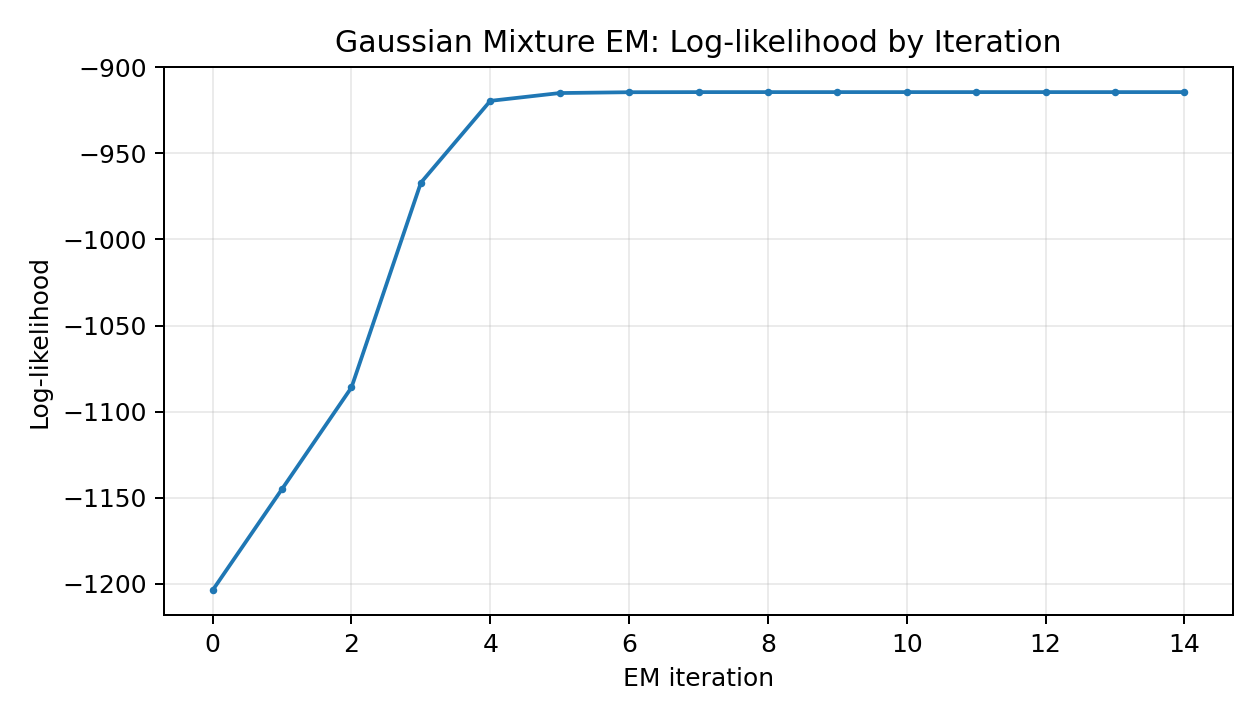

In [19]:
fits_df=pd.DataFrame(fits)
modelsel_df=pd.DataFrame(modelsel)
display(fits_df.style.format({c:'{:.5f}' for c in fits_df.select_dtypes('number').columns}))
print('BIC comparison: lower BIC is preferred')
display(modelsel_df.style.format({c:'{:.5f}' for c in modelsel_df.select_dtypes('number').columns}))
comparison_df=pd.DataFrame([
    {'Method':'Soft EM','Log-likelihood':best2['loglik'],'Iterations':best2['iterations'],'Means':str(best2['mu'].round(4).tolist())},
    {'Method':'Hard assignment','Log-likelihood':hard['loglik'],'Iterations':hard['iterations'],'Means':str(hard['mu'].round(4).tolist())},
])
display(comparison_df.style.format({'Log-likelihood':'{:.5f}'}))
q5_fig=os.path.join(FIG,'q5_em_loglik.png')
display(Image(filename=q5_fig))


## Q6 – Investigate Sample Complexity, Hypothesis Space Capacity and Mistake Bounds (8 marks)

This question reports finite-hypothesis PAC bounds, VC-dimension bounds for three hypothesis classes, a Find-S simulation, Halving's mistake count, and an online conjunction learner over 500 random trials. The empirical PAC curve is generated here in Q6, beside the PAC calculations.


In [20]:
# ---------------- Q6 sample complexity, VC dimension, mistake bounds ----------------
n=10
H_size=3**n+1
pac=[]
for eps in [.1,.05]:
    for delta in [.05,.01]:
        raw=(math.log(H_size)+math.log(1/delta))/eps
        pac.append({'n':n,'epsilon':eps,'delta':delta,'H_size':H_size,'bound_raw':raw,'m_ceiling':math.ceil(raw)})
# sample size variation data
sample_n=[]
for nn in range(2,31,2):
    hh=3**nn+1
    for eps in [.1,.05]:
        for delta in [.05,.01]:
            sample_n.append({'n':nn,'epsilon':eps,'delta':delta,'m':math.ceil((math.log(hh)+math.log(1/delta))/eps)})
# VC bound values
vcclasses=[('Intervals on real line',2),('Linear separators in plane',3),('Axis-aligned rectangles in plane',4)]
vc_bounds=[]
for name,dvc in vcclasses:
    eps=.1; delta=.05
    val=(1/eps)*(4*math.log2(2/delta)+8*dvc*math.log2(13/eps))
    vc_bounds.append({'class':name,'VC_dimension':dvc,'bound_raw':val,'m_ceiling':math.ceil(val)})
# PAC simulation Find-S for monotone conjunction target on first 3 of 10 vars
rng_pac=np.random.default_rng(6606)
Nfeatures=10; target_literals={0:1,1:1,2:0}
allX=np.array(list(itertools.product([0,1],repeat=Nfeatures)),dtype=int)
def target_label(X):
    out=np.ones(len(X),dtype=int)
    for j,v in target_literals.items(): out &= (X[:,j]==v)
    return out
def find_s_learn(X,y,nf):
    h=[None]*nf
    for x,label in zip(X,y):
        if label==1:
            if all(v is None for v in h): h=list(x)
            else:
                h=[old if old is None or old==int(x[j]) else None for j,old in enumerate(h)]
    return h
def find_s_predict(h,X):
    pred=np.ones(len(X),dtype=int)
    for j,v in enumerate(h):
        if v is not None: pred &= (X[:,j]==v)
    return pred
true_all=target_label(allX)
ms=sorted(set([10,20,40,80,120,200,300]))
# Include a computed PAC bound for epsilon=.1, delta=.05
bound_01_005=next(x['m_ceiling'] for x in pac if x['epsilon']==.1 and x['delta']==.05)
ms=sorted(set(ms+[bound_01_005]))
trials=200; pac_sim=[]
for m in ms:
    errs=[]
    for t in range(trials):
        XX=rng_pac.integers(0,2,size=(m,Nfeatures)); yy=target_label(XX)
        h=find_s_learn(XX,yy,Nfeatures)
        err=float(np.mean(find_s_predict(h,allX)!=true_all)); errs.append(err)
    pac_sim.append({'m':m,'trials':trials,'mean_true_error':float(np.mean(errs)),
                    'fraction_error_le_epsilon_0.1':float(np.mean(np.array(errs)<=.1)),
                    'fraction_error_le_epsilon_0.05':float(np.mean(np.array(errs)<=.05))})
# Plot sample complexity bounds
fig,ax=plt.subplots(figsize=(7,4))
for eps,delta in itertools.product([.1,.05],[.05,.01]):
    xs=[]; ys=[]
    for nn in range(2,31):
        xs.append(nn); ys.append(math.ceil((math.log(3**nn+1)+math.log(1/delta))/eps))
    ax.plot(xs,ys,label=f'epsilon={eps}, delta={delta}')
ax.set_xlabel('Number of Boolean features n'); ax.set_ylabel('PAC sample bound m'); ax.set_title('Finite-Hypothesis PAC Sample Complexity'); ax.legend(fontsize=8); ax.grid(alpha=.25); fig.tight_layout(); fig.savefig(os.path.join(FIG,'q6_pac_sample_bound.png'),dpi=180); plt.close(fig)
pd.DataFrame(pac).to_csv(os.path.join(RES,'q6_pac_bounds_n10.csv'),index=False)
pd.DataFrame(pac_sim).to_csv(os.path.join(RES,'q6_pac_find_s_simulation.csv'),index=False)
pd.DataFrame(vc_bounds).to_csv(os.path.join(RES,'q6_vc_bounds.csv'),index=False)
# Halving algorithm H=all 2^6 binary label vectors over 6 domain points
H6=list(itertools.product([0,1],repeat=6)); V=list(H6); seq=[]; mistakes=0
for j in range(6):
    ones=sum(h[j] for h in V); zeros=len(V)-ones
    pred=1 if ones>zeros else 0 # ties choose 0
    # Adversary chooses opposite majority, yielding one mistake (fixed hypothesis is final sequence)
    y=1-pred
    seq.append({'step':j+1,'consistent_before':len(V),'vote_ones':ones,'vote_zeros':zeros,'prediction':pred,'label':y,'mistake':int(pred!=y)})
    V=[h for h in V if h[j]==y]; mistakes+=int(pred!=y)
# final target is the only consistent hypothesis
halving_target=V[0]
# Conjunction online learner starts bottom, on first positive set matching literals, on later positive drop contradicted literals

def online_conjunction(X,y):
    nfeat=X.shape[1]; h=None; mistakes=0; trace=[]
    for i,(x,label) in enumerate(zip(X,y)):
        pred=0 if h is None else int(all(h[j] is None or h[j]==int(x[j]) for j in range(nfeat)))
        miss=int(pred!=int(label)); mistakes+=miss
        if label==1:
            if h is None: h=list(map(int,x))
            else: h=[old if old is None or old==int(x[j]) else None for j,old in enumerate(h)]
        trace.append({'step':i+1,'prediction':pred,'label':int(label),'mistake':miss,'hypothesis':h.copy() if h is not None else None})
    return mistakes,h,trace
rng_online=np.random.default_rng(6707); online_tests=[]
for t in range(500):
    ntarget=int(rng_online.integers(0,Nfeatures+1))
    sel=rng_online.choice(Nfeatures,size=ntarget,replace=False)
    target={int(j):int(rng_online.integers(0,2)) for j in sel}
    XX=rng_online.integers(0,2,size=(100,Nfeatures))
    yy=np.ones(len(XX),dtype=int)
    for j,v in target.items(): yy &= (XX[:,j]==v)
    # Shuffle examples to vary order
    order=rng_online.permutation(len(XX)); mm,hh,tt=online_conjunction(XX[order],yy[order])
    online_tests.append(mm)
# relation VC <= Opt <= log2|C| for thresholds on 3 ordered points
relation={'class':'thresholds on ordered domain {1,2,3}','concept_count':4,'VC_dimension':1,'optimal_mistake_bound':2,'log2_concept_count':2}
results['q6']={'finite_H_size_n10':H_size,'pac_bounds':pac,'pac_simulation':pac_sim,'vc_bounds':vc_bounds,
 'halving_sequence':seq,'halving_mistakes':mistakes,'halving_bound_log2H':math.log2(64),'halving_final_hypothesis':halving_target,
 'online_conjunction_trials':len(online_tests),'online_max_mistakes':int(max(online_tests)),'online_mean_mistakes':float(np.mean(online_tests)),
 'online_bound_n_plus_1':Nfeatures+1,'online_mistakes_distribution':dict(Counter(online_tests)),
 'vc_opt_log_relation':relation,'seed':6606}



### Q6 results – expanded PAC simulation and learning-theory tables

,n,epsilon,delta,H_size,bound_raw,m_ceiling
0,10,0.100000,0.050000,59050,139.819,140
1,10,0.100000,0.010000,59050,155.913,156
2,10,0.050000,0.050000,59050,279.637,280
3,10,0.050000,0.010000,59050,311.826,312


,class,VC_dimension,bound_raw,m_ceiling
0,Intervals on real line,2,1336.456,1337
1,Linear separators in plane,3,1898.245,1899
2,Axis-aligned rectangles in plane,4,2460.035,2461


,m,trials,mean_true_error,fraction_error_le_epsilon_0.1,fraction_error_le_epsilon_0.05
0,10,200,0.2947,0.120,0.015
1,20,200,0.1548,0.440,0.140
2,40,200,0.0445,0.860,0.505
3,80,200,0.0035,0.995,0.950
4,120,200,0.0009,1.000,0.985
5,140,200,0.0000,1.000,1.000
6,156,200,0.0000,1.000,1.000
7,200,200,0.0000,1.000,1.000
8,280,200,0.0000,1.000,1.000
9,300,200,0.0000,1.000,1.000


,step,consistent_before,vote_ones,vote_zeros,prediction,label,mistake
0,1,64,32,32,0,1,1
1,2,32,16,16,0,1,1
2,3,16,8,8,0,1,1
3,4,8,4,4,0,1,1
4,5,4,2,2,0,1,1
5,6,2,1,1,0,1,1


,Number of trials,Observed maximum mistakes,Mean mistakes,Theoretical n+1 bound,Halving mistakes,log2(|H|) bound
0,500,7,2.556,11,6,6.0


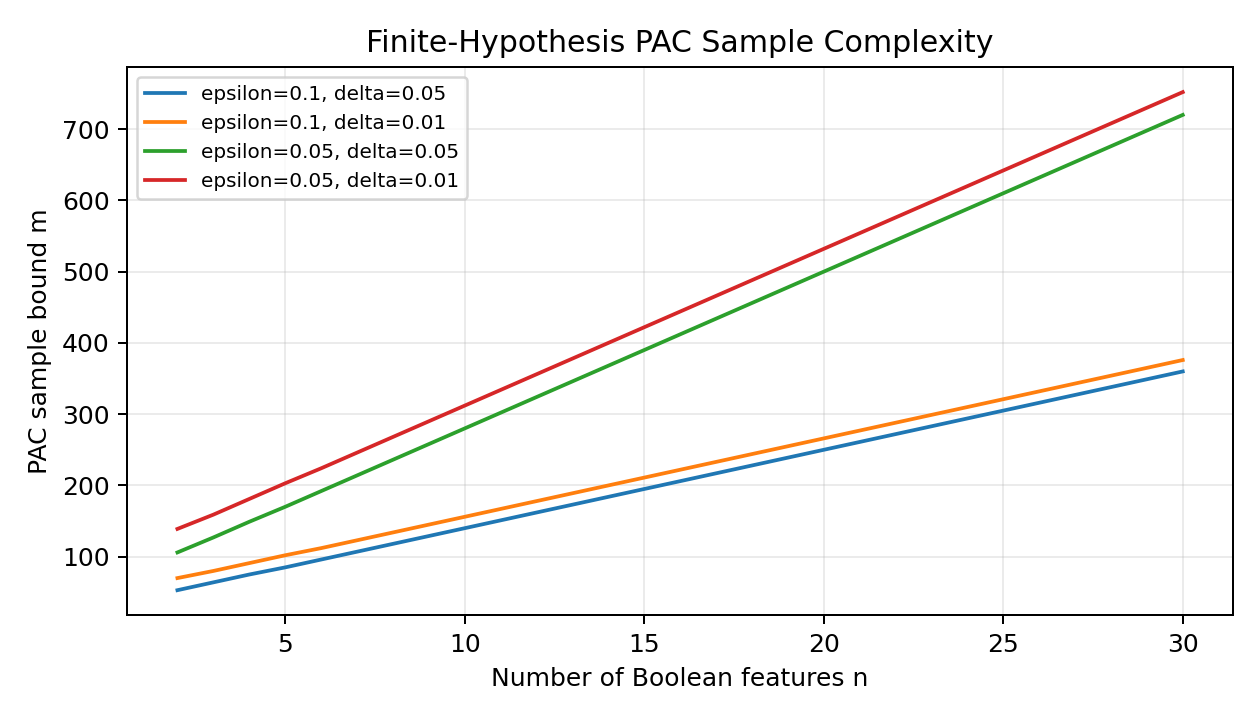

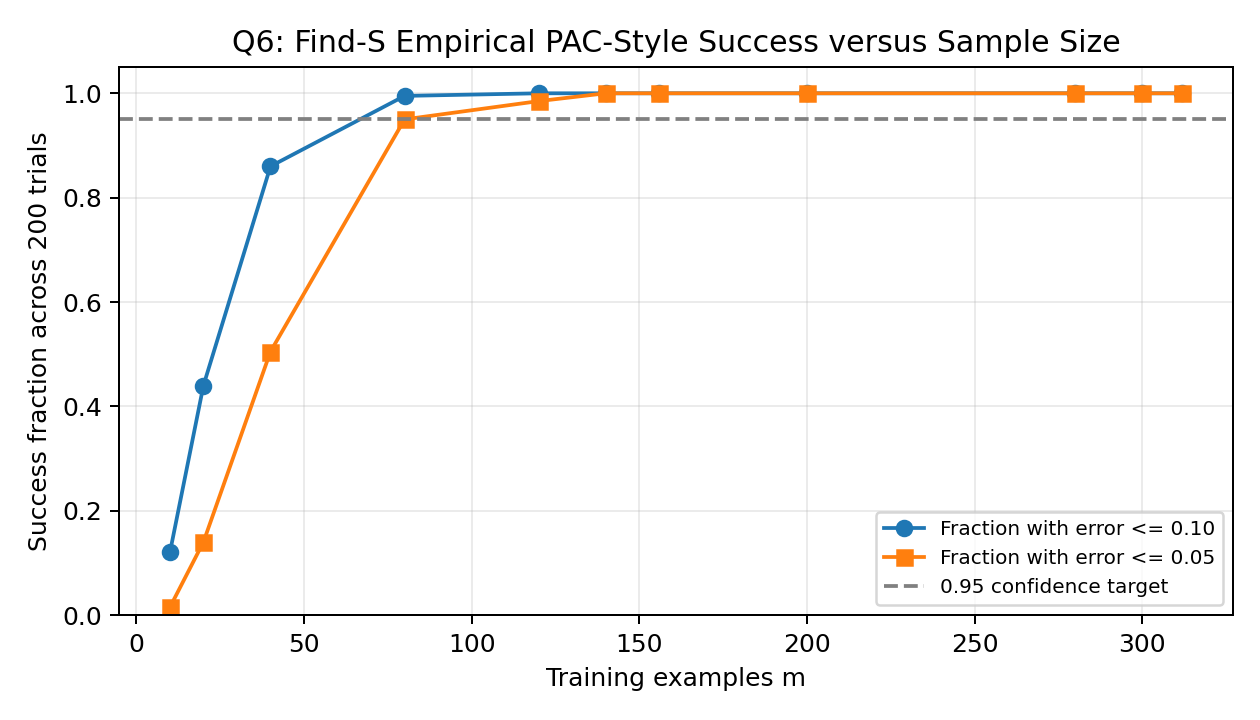

In [21]:
# Extend the PAC simulation to include all four required (epsilon, delta) sample bounds.
all_bound_sizes=sorted(set([x['m_ceiling'] for x in pac]))
ms=sorted(set(ms+all_bound_sizes))
rng_pac2=np.random.default_rng(6616)
pac_sim2=[]
for m in ms:
    errs=[]
    for t in range(trials):
        XX=rng_pac2.integers(0,2,size=(m,Nfeatures)); yy=target_label(XX)
        h=find_s_learn(XX,yy,Nfeatures)
        errs.append(float(np.mean(find_s_predict(h,allX)!=true_all)))
    pac_sim2.append({'m':m,'trials':trials,'mean_true_error':float(np.mean(errs)),
                     'fraction_error_le_epsilon_0.1':float(np.mean(np.array(errs)<=.1)),
                     'fraction_error_le_epsilon_0.05':float(np.mean(np.array(errs)<=.05))})
pd.DataFrame(pac_sim2).to_csv(os.path.join(RES,'q6_pac_find_s_simulation.csv'),index=False)
results['q6']['pac_simulation']=pac_sim2
results['q6']['pac_simulation_seed']=6616

pac_df=pd.DataFrame(pac)
vc_df=pd.DataFrame(vc_bounds)
pac_sim_df=pd.DataFrame(pac_sim2)
display(pac_df.style.format({'bound_raw':'{:.3f}'}))
display(vc_df.style.format({'bound_raw':'{:.3f}'}))
display(pac_sim_df.style.format({'mean_true_error':'{:.4f}','fraction_error_le_epsilon_0.1':'{:.3f}',
                                  'fraction_error_le_epsilon_0.05':'{:.3f}'}))

halving_df=pd.DataFrame(seq)
display(halving_df)
online_df=pd.DataFrame([{'Number of trials':len(online_tests),'Observed maximum mistakes':int(max(online_tests)),
                         'Mean mistakes':float(np.mean(online_tests)),'Theoretical n+1 bound':Nfeatures+1,
                         'Halving mistakes':mistakes,'log2(|H|) bound':math.log2(64)}])
display(online_df.style.format({'Mean mistakes':'{:.3f}','log2(|H|) bound':'{:.1f}'}))

# Empirical PAC success curve is generated and displayed in the Q6 section.
fig,ax=plt.subplots(figsize=(7,4)); xx=[x['m'] for x in pac_sim2]
ax.plot(xx,[x['fraction_error_le_epsilon_0.1'] for x in pac_sim2],marker='o',label='Fraction with error <= 0.10')
ax.plot(xx,[x['fraction_error_le_epsilon_0.05'] for x in pac_sim2],marker='s',label='Fraction with error <= 0.05')
ax.axhline(.95,linestyle='--',color='gray',label='0.95 confidence target')
ax.set_xlabel('Training examples m'); ax.set_ylabel('Success fraction across 200 trials')
ax.set_ylim(0,1.05); ax.set_title('Q6: Find-S Empirical PAC-Style Success versus Sample Size')
ax.legend(fontsize=8); ax.grid(alpha=.25); fig.tight_layout()
q6_sim_fig=os.path.join(FIG,'q6_pac_simulation.png'); fig.savefig(q6_sim_fig,dpi=180); plt.close(fig)
display(Image(filename=os.path.join(FIG,'q6_pac_sample_bound.png')))
display(Image(filename=q6_sim_fig))


## Q7 – Diagnose, Redesign and Validate a Bayesian or Computational Learning Solution (13 marks)

The selected limitation is the conditional-independence assumption in Naïve Bayes when two input features are strongly correlated. The redesign removes one redundant copy and compares the original and revised models on the same fixed train/test split.


In [22]:
# ---------------- Q7 redesign: de-duplicate redundant feature in NB ----------------
# Baseline = NB with X1 and strongly correlated X2 plus X3. Redesigned = remove X2.
q7_baseline=next(x for x in exp_nb if x['model']=='with_redundant')
q7_redesign=next(x for x in exp_nb if x['model']=='without_redundant')
results['q7']={'diagnosis':'Naive Bayes treats the strongly correlated duplicate X2 as conditionally independent evidence, which can double-count the same signal and distort posterior confidence.',
 'objective':'Reduce held-out log-loss while keeping accuracy no more than 2 percentage points below the baseline.',
 'baseline':q7_baseline,'redesign':q7_redesign,
 'decision':'Remove the redundant copy feature; retain the original informative feature and independent weak feature.',
 'prediction':'Expected to reduce posterior overconfidence and improve or preserve log-loss; accuracy may remain similar.'}

# save result json
with open(os.path.join(RES,'assignment3_results.json'),'w') as f: json.dump(results,f,indent=2,default=lambda o: list(o) if isinstance(o,tuple) else str(o))
# Summary text
print('Q1',json.dumps(results['q1_bayes'],indent=2))
print('Q1 concept VS',VS3,'S6',S6,'G6',G6,'nonuniform',post_nonuniform)
print('Q2',json.dumps(results['q2'],indent=2))
print('Q3',json.dumps(results['q3'],indent=2))
print('Q4',json.dumps(results['q4'],indent=2))
print('Q5',json.dumps({k:v for k,v in results['q5'].items() if k not in ['manual_responsibilities','em_multistart']},indent=2))
print('Q6',json.dumps(results['q6'],indent=2))
print('Q7',json.dumps(results['q7'],indent=2))
print('Figures:',os.listdir(FIG))



Q1 {
  "P_positive": 0.1061,
  "posterior_one_positive": 0.26861451460885954,
  "posterior_two_independent_positives": 0.813478352311991,
  "prior": 0.03,
  "sensitivity": 0.95,
  "false_positive_rate": 0.08
}
Q1 concept VS [('High', 'Heavy', '?'), ('High', '?', '?'), ('?', 'Heavy', '?')] S6 ('?', 'Heavy', '?') G6 [('?', 'Heavy', '?')] nonuniform {"('High', 'Heavy', '?')": 0.23076923076923078, "('High', '?', '?')": 0.46153846153846156, "('?', 'Heavy', '?')": 0.3076923076923077}
Q2 {
  "tree_A_bits": 133.1508495181978,
  "tree_B_bits": 307.64385618977474,
  "preferred_tree": "A",
  "node_cost_reversal_bits": 2.8161575436012143,
  "posterior_plus": 0.44999999999999996,
  "posterior_minus": 0.55,
  "bayes_optimal_prediction": "-",
  "MAP_hypothesis": "h1",
  "MAP_prediction": "+",
  "gibbs_expected_error": 0.495,
  "bayes_optimal_expected_error": 0.44999999999999996,
  "gibbs_upper_bound_2_bayes": 0.8999999999999999,
  "monte_carlo_draws": 200000,
  "monte_carlo_gibbs_error": 0.494505
}
Q

### Q7 results – baseline versus redesigned model

,Metric,Baseline: duplicate included,Redesign: duplicate removed,Change
0,Accuracy,0.822500,0.827500,0.005000
1,Log-loss,0.551920,0.453632,-0.098289


Redesign objective: Reduce held-out log-loss while keeping accuracy no more than 2 percentage points below the baseline.
Prediction before implementation: Expected to reduce posterior overconfidence and improve or preserve log-loss; accuracy may remain similar.
Relative log-loss reduction: 17.81 %


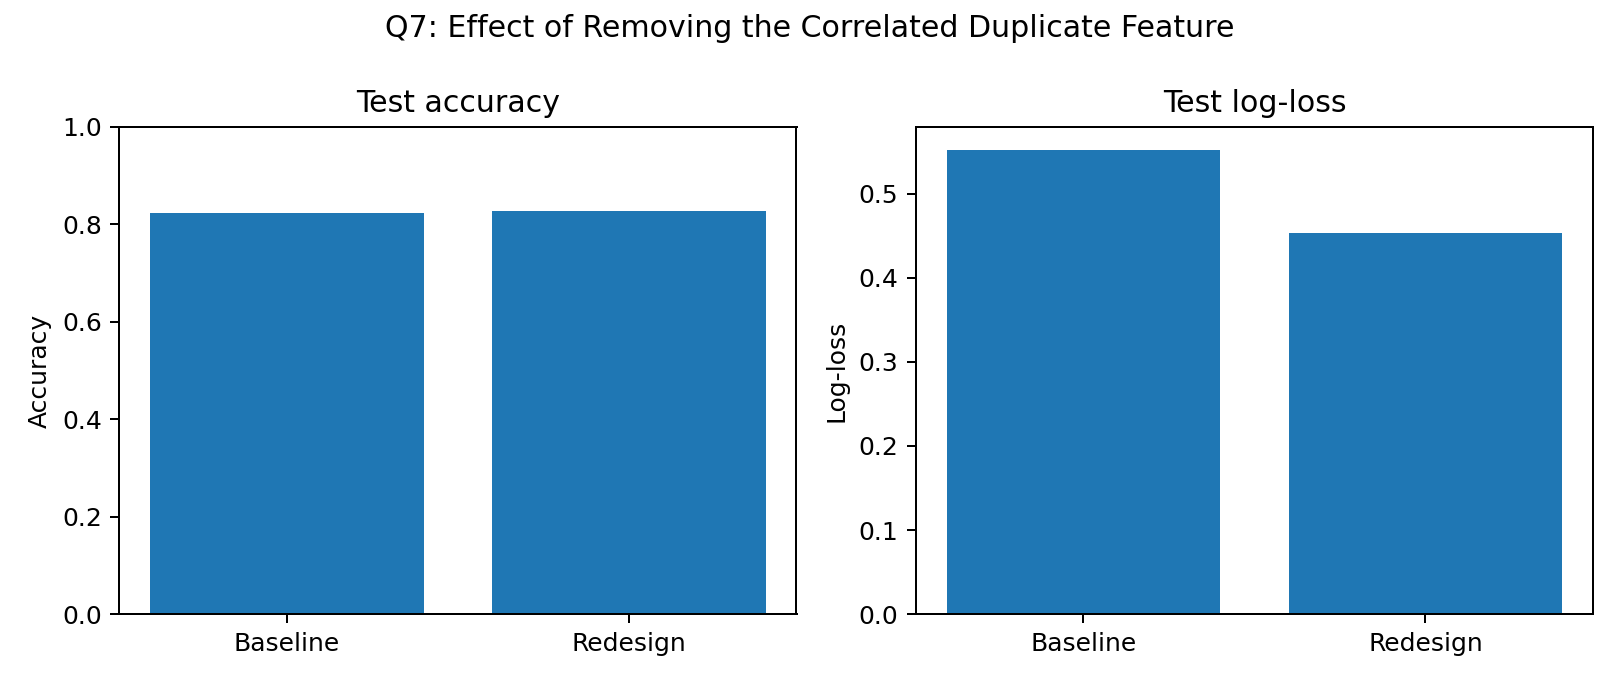

In [23]:
results['q7']['log_loss_absolute_reduction']=q7_baseline['log_loss']-q7_redesign['log_loss']
results['q7']['log_loss_relative_reduction_percent']=100*(q7_baseline['log_loss']-q7_redesign['log_loss'])/q7_baseline['log_loss']
results['q7']['accuracy_change_percentage_points']=100*(q7_redesign['accuracy']-q7_baseline['accuracy'])
q7_compare_df=pd.DataFrame([
    {'Metric':'Accuracy','Baseline: duplicate included':q7_baseline['accuracy'],
     'Redesign: duplicate removed':q7_redesign['accuracy'],
     'Change':q7_redesign['accuracy']-q7_baseline['accuracy']},
    {'Metric':'Log-loss','Baseline: duplicate included':q7_baseline['log_loss'],
     'Redesign: duplicate removed':q7_redesign['log_loss'],
     'Change':q7_redesign['log_loss']-q7_baseline['log_loss']},
])
display(q7_compare_df.style.format({c:'{:.6f}' for c in q7_compare_df.select_dtypes('number').columns}))
print('Redesign objective:',results['q7']['objective'])
print('Prediction before implementation:',results['q7']['prediction'])
print('Relative log-loss reduction:',round(results['q7']['log_loss_relative_reduction_percent'],2),'%')

fig,axes=plt.subplots(1,2,figsize=(9,3.8))
labels=['Baseline','Redesign']
axes[0].bar(labels,[q7_baseline['accuracy'],q7_redesign['accuracy']])
axes[0].set_ylim(0,1); axes[0].set_title('Test accuracy'); axes[0].set_ylabel('Accuracy')
axes[1].bar(labels,[q7_baseline['log_loss'],q7_redesign['log_loss']])
axes[1].set_title('Test log-loss'); axes[1].set_ylabel('Log-loss')
fig.suptitle('Q7: Effect of Removing the Correlated Duplicate Feature')
fig.tight_layout()
q7_fig=os.path.join(FIG,'q7_redesign_comparison.png'); fig.savefig(q7_fig,dpi=180); plt.close(fig)
display(Image(filename=q7_fig))


## Final export and reproducibility check

This final cell only lists generated data and result files. All tables, diagrams and experiment plots have already appeared inside their relevant Q1–Q7 sections above.


In [24]:
with open(os.path.join(RES,'assignment3_results.json'),'w') as f:
    json.dump(results,f,indent=2,default=lambda o: list(o) if isinstance(o,tuple) else str(o))
print('Output directory:', OUT)
print('Result files:')
for f in sorted(os.listdir(RES)):
    print(' -',f)
print('Figure files:')
for f in sorted(os.listdir(FIG)):
    print(' -',f)


Output directory: /content/assignment3_outputs
Result files:
 - assignment3_results.json
 - q3_correlated_features_4000.csv
 - q3_loan_data.csv
 - q4_bn_simulated_1000.csv
 - q4_cpt_estimates.csv
 - q5_em_10_initialisations.csv
 - q5_em_loglik_history.csv
 - q5_gmm_500.csv
 - q5_gmm_model_selection.csv
 - q5_manual_em_responsibilities.csv
 - q6_pac_bounds_n10.csv
 - q6_pac_find_s_simulation.csv
 - q6_vc_bounds.csv
Figure files:
 - q1_version_space_lattice.png
 - q2_mdl_sensitivity.png
 - q3_redundant_feature_comparison.png
 - q4_bayesian_network.png
 - q5_em_loglik.png
 - q6_pac_sample_bound.png
 - q6_pac_simulation.png
 - q7_redesign_comparison.png
